# IPF — sRGES pipeline (drug summarisation after CS) vs TSR/LMM pipeline

Two ways of turning LINCS L1000 drug signatures into one score per drug, on the same ipf disease
signature (GSE92592, lung tissue, 20 IPF vs 19 controls):

| | **TSR/LMM pipeline** | **sRGES pipeline** (Chen 2017 / OCTAD) |
|---|---|---|
| drug signatures | level-3 L1000, collapsed per drug **before** CS by a linear mixed model (cell line `all`) | level-5 landmark signatures, **one per instance** (drug × cell line × dose × time), 71 cell lines |
| CS | one per drug (pooled `6h_24h` used here) | one per instance |
| run names | `<config>_TSR` (e.g. `DEG_TSR`) | `<config>` + score |
| per-drug score | the CS itself | collapse **after** CS: `sRGES_weighted` (cell lines weighted by CCLE similarity to the IPF lung samples), `sRGES_unweighted`, `best` (most negative instance) |
| drug universe | 3,221 compounds | 12,440 compounds (BRD ids with the same L1000 name pooled; section 2.1) |

Sign convention for every score: **more negative = stronger reversal = better candidate**.

Inputs (tables of `src/case_study_pipeline.py`, steps `weights`, `srges` and `validation` of
`src/case_study/`): `ipf_cell_line_weights.tsv` (weights), `ipf_srges_per_drug.tsv` (per-drug sRGES),
`ipf_known_drug_ranks.tsv` (known drugs in every ranking). TSR runs via `loader.load_cs_run(drug_run_id='all')`.
Known drugs: pirfenidone and nintedanib (approved, disease-modifying). With 2 known drugs the comparison is descriptive: it shows where they fall, it does
not measure the performance of a ranking.

Configurations: `DEG`, `mith`, `mith_LM`, `mith_pw`; each section shows every configuration with CS runs
on all 71 cell lines. In this route `DEG_LM` = `DEG` (the drug signatures are landmark-only).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'axes.grid': True, 'grid.color': '0.75', 'grid.linestyle': '--', 'grid.linewidth': .6})
BLUE, RED = '#1f4e9c', '#c0392b'

DISEASE = 'ipf'
def _find_root(start):
    p = start
    for _ in range(8):
        if os.path.isdir(os.path.join(p, 'connectivity_score', 'input')):
            return p
        p = os.path.dirname(p)
    return None
NETCOS_ROOT = _find_root(os.getcwd())
sys.path.insert(0, os.path.join(NETCOS_ROOT, 'src'))
from loader import load_cs_run

OUT = os.path.join(NETCOS_ROOT, 'other_outputs', 'case_studies', DISEASE)
IMG_DIR = os.path.join(NETCOS_ROOT, 'imgs', 'case_studies', DISEASE)
os.makedirs(IMG_DIR, exist_ok=True)
N_LINES = 71

srges = pd.read_csv(os.path.join(OUT, f'{DISEASE}_srges_per_drug.tsv'), sep='\t')
runs_used = pd.read_csv(os.path.join(OUT, f'{DISEASE}_srges_cs_runs_used.tsv'), sep='\t')
weights = pd.read_csv(os.path.join(OUT, f'{DISEASE}_cell_line_weights.tsv'), sep='\t')
kn = pd.read_csv(os.path.join(OUT, f'{DISEASE}_known_drug_ranks.tsv'), sep='\t')
KNOWN = list(kn.drug_key.unique())

complete = runs_used.groupby('config')['cell_line'].nunique()
CONFIGS = [c for c in ['DEG', 'mith', 'mith_LM', 'mith_pw'] if complete.get(c, 0) == N_LINES]
PENDING = [c for c in ['DEG', 'mith', 'mith_LM', 'mith_pw'] if c not in CONFIGS]
COLLAPSES = ['sRGES_weighted', 'sRGES_unweighted', 'best']
print('cell lines with a CS run per configuration:', complete.to_dict())
print('shown:', CONFIGS, '| without CS runs on all lines:', PENDING)

cell lines with a CS run per configuration: {'DEG': 71, 'mith': 71, 'mith_LM': 71, 'mith_pw': 71}
shown: ['DEG', 'mith', 'mith_LM', 'mith_pw'] | without CS runs on all lines: []


## 1. TSR/LMM drug-collapsed runs (reference, `<config>_TSR`)

The most recent `bin_chen` run of each configuration on drug input `all`, pooled `6h_24h` rows,
drug key = L1000 name (lower case, alphanumerics only).

In [2]:
TSR_CONFIGS = {'DEG': (0, 0, 0), 'DEG_LM': (0, 1, 0), 'mith': (1, 0, 0), 'mith_LM': (1, 1, 0), 'mith_pw': (1, 0, 1)}
key = lambda s: s.astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
tsr = {}
for lab, (m, lm, pw) in TSR_CONFIGS.items():
    df, path, run_id = load_cs_run(disease=DISEASE, landmark_disease=False, drug_run_id='all', mith=m, cs_on_LM=lm,
                                   CS_ON_PATHWAYS=pw, CS_METHOD='bin_chen', verbose=False)
    p = df[df['pert_id'].astype(str).str.endswith('_6h_24h')].copy()
    p['k'] = key(p['pert_id'].str[:-len('_6h_24h')])
    tsr[lab] = p.groupby('k')['connectivity_score'].mean()
    print(f'{lab + "_TSR":12s} {run_id}  drugs {len(tsr[lab])}')

DEG_TSR      30_06_2026_10_49_DEG_bin_chen_connectivity_score  drugs 3221
DEG_LM_TSR   30_06_2026_13_00_DEG_LM_bin_chen_connectivity_score  drugs 3221
mith_TSR     30_06_2026_13_00_mith_bin_chen_connectivity_score  drugs 3221


mith_LM_TSR  30_06_2026_13_05_mith_LM_bin_chen_connectivity_score  drugs 3221
mith_pw_TSR  21_06_2026_17_28_mith_pw_bin_chen_connectivity_score  drugs 3221


## 2. Coverage of the sRGES pipeline

In [3]:
s = srges[srges['config'].isin(CONFIGS)].copy()
s['k'] = key(s['pert_iname'])
cov = s.groupby(['config', 'collapse']).agg(n_drugs=('pert_iname', 'size'), compounds_several_BRD=('n_pert_ids', lambda x: int((x > 1).sum())),
        median_instances=('n_instances', 'median'), drugs_1_instance=('n_instances', lambda x: int((x == 1).sum())),
        median_cell_lines=('n_cell_lines', 'median'), drugs_1_cell_line=('n_cell_lines', lambda x: int((x == 1).sum())))
display(cov)
for c in CONFIGS:
    names = set(s.loc[(s.config == c) & (s.collapse == 'sRGES_unweighted'), 'k'])
    t = set(tsr[c].index)
    print(f'{c}: sRGES compounds {len(names)}, {c}_TSR {len(t)}, shared {len(names & t)}, {c}_TSR-only {len(t - names)}')
lost = 1 - s.loc[s.collapse == 'sRGES_weighted'].groupby('config').size() / s.loc[s.collapse == 'sRGES_unweighted'].groupby('config').size()
print('share of compounds lost by the weighted sRGES (only on lines without a CCLE weight):', lost.round(3).to_dict())

n_drugs  compounds_several_BRD  median_instances  drugs_1_instance  median_cell_lines  drugs_1_cell_line
config  collapse                                                                                                                             
DEG     best                           12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted               12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted_top_median     2644                    332               1.0              1666                1.0               2234
        sRGES_weighted                 12168                    424               2.0              5072                1.0               6159
        sRGES_weighted_top_median       2644                    332               1.0              1666                1.0               2234
mith    best                           12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted               12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted_top_median     2644                    332               1.0              1666                1.0               2234
        sRGES_weighted                 12168                    424               2.0              5072                1.0               6159
        sRGES_weighted_top_median       2644                    332               1.0              1666                1.0               2234
mith_LM best                           12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted               12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted_top_median     2644                    332               1.0              1666                1.0               2234
        sRGES_weighted                 12168                    424               2.0              5072                1.0               6159
        sRGES_weighted_top_median       2644                    332               1.0              1666                1.0               2234
mith_pw best                           12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted               12442                    426               2.0              5041                2.0               6075
        sRGES_unweighted_top_median     2644                    332               1.0              1666                1.0               2234
        sRGES_weighted                 12168                    424               2.0              5072                1.0               6159
        sRGES_weighted_top_median       2644                    332               1.0              1666                1.0               2234

DEG: sRGES compounds 12440, DEG_TSR 3221, shared 3076, DEG_TSR-only 145
mith: sRGES compounds 12440, mith_TSR 3221, shared 3076, mith_TSR-only 145
mith_LM: sRGES compounds 12440, mith_LM_TSR 3221, shared 3076, mith_LM_TSR-only 145
mith_pw: sRGES compounds 12440, mith_pw_TSR 3221, shared 3076, mith_pw_TSR-only 145
share of compounds lost by the weighted sRGES (only on lines without a CCLE weight): {'DEG': 0.022, 'mith': 0.022, 'mith_LM': 0.022, 'mith_pw': 0.022}


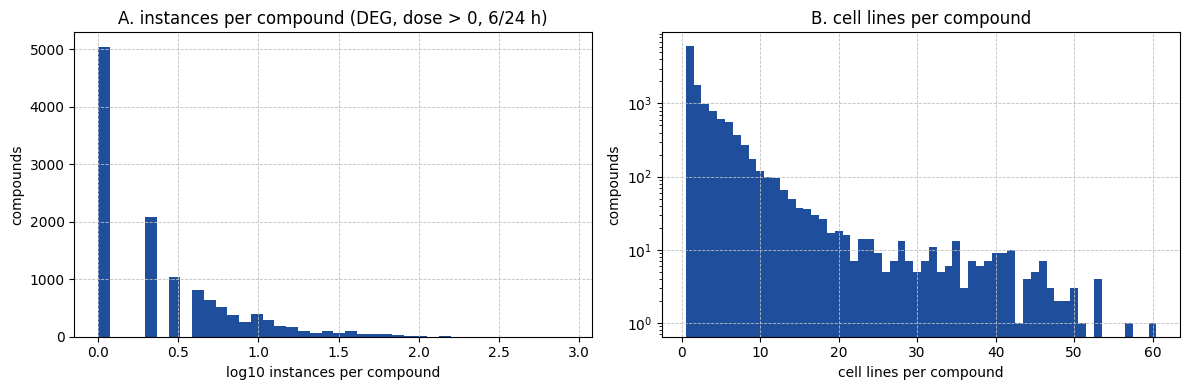

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
u = s[(s.collapse == 'sRGES_unweighted') & (s.config == CONFIGS[0])]
ax[0].hist(np.log10(u['n_instances']), bins=40, color=BLUE)
ax[0].set_xlabel('log10 instances per compound'); ax[0].set_ylabel('compounds')
ax[0].set_title(f'A. instances per compound ({CONFIGS[0]}, dose > 0, 6/24 h)')
ax[1].hist(u['n_cell_lines'], bins=np.arange(0.5, u['n_cell_lines'].max() + 1.5), color=BLUE)
ax[1].set_xlabel('cell lines per compound'); ax[1].set_ylabel('compounds'); ax[1].set_yscale('log')
ax[1].set_title('B. cell lines per compound')
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_coverage.png'), dpi=120); plt.show()

### 2.1 Drug universes: own universe vs shared (TSR ∩ per-instance)

Both routes give **one score per compound**: the TSR route after the per-drug LMM, the
per-instance route after collapsing the instance CS (`sRGES`, `wsRGES`, `best`).
Percentiles are computed over compounds, keyed on `drug_key` (normalised L1000 name;
all BRD ids of a name pooled). Cell lines only decide which instances enter a compound's score.

**Own universe** = the compounds a ranking scores:
- TSR rankings (all 5 configurations): 3,221 compounds (GSE92742 level 3, all instances).
- `sRGES` / `best`: 12,440 compounds (Chen 2017 level-5 gold set, 66,511 instances,
  dose > 0 at 6 or 24 h, all 71 lines).
- `wsRGES`: 12,166 compounds (only the 58 lines with a CCLE weight; compounds profiled
  only on the 13 unweighted lines drop out).
- Top-line rankings (`_topQ3`, `_topMed`, section 10): only the compounds profiled on at least
  one top line.

**Shared set** (`percentile_shared_DEG` in the tables; "TSR ∩ per-instance" in the plots) =
the 3,076 compounds in both universes (3,053 for `wsRGES`). It depends only on which
compounds the two LINCS pools contain, not on the disease signature, so it is the same
for every configuration (`DEG`, `mith`, `mith_LM`, `mith_pw`); the "DEG" in the column name
only marks where it was first defined.

**Why the universes differ:**
- *TSR-only (145):* no instance passes the gold-set filter. Most are compounds absent from
  the gold set (BRD codes, tool compounds, some drugs, e.g. chlorthalidone, guanfacine,
  ixazomib, sonidegib); the others are esters, salts or prodrugs whose parent compound is in the
  gold set under its own name (e.g. dexamethasone acetate, hydrocortisone acetate / valerate /
  hemisuccinate, prednisolone acetate, retinyl acetate).
- *Per-instance-only (9,364):* compounds the TSR/LMM step did not keep, among them compounds
  profiled only at 6 h (count in the cell below).

In [5]:
def pct(s):
    """Percentile within a ranking: rank(pct) x 100, ascending score (low = stronger reversal)."""
    return s.rank(pct=True) * 100


def consensus(W, cols):
    """Percentiles recomputed on the compounds scored by every ranking in cols, then averaged."""
    P = W[cols].dropna().apply(pct)
    P['mean_pct'] = P.mean(axis=1)
    P['consensus_rank'] = P['mean_pct'].rank(method='min').astype(int)
    return P.sort_values('mean_pct')


# one score per compound for every ranking: TSR (section 1, pooled 6h_24h) and per-instance collapses
REN = {'sRGES_unweighted': 'sRGES', 'sRGES_weighted': 'wsRGES', 'best': 'best',
       'sRGES_unweighted_top_q3': 'sRGES_topQ3', 'sRGES_weighted_top_q3': 'wsRGES_topQ3',
       'sRGES_unweighted_top_median': 'sRGES_topMed', 'sRGES_weighted_top_median': 'wsRGES_topMed'}
_sp = srges.assign(k=srges['pert_iname'].astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True))
_sp['ranking'] = _sp['config'] + '_' + _sp['collapse'].map(REN)
W = pd.concat([_sp.groupby(['k', 'ranking'])['score'].mean().unstack()] +
              [v.rename(f'{cfg}_TSR') for cfg, v in tsr.items()], axis=1)
NAME = _sp.drop_duplicates('k').set_index('k')['pert_iname'].reindex(W.index)
NAME = NAME.fillna(pd.Series(W.index, index=W.index))


u_tsr, u_pi = set(W['DEG_TSR'].dropna().index), set(W['DEG_sRGES'].dropna().index)
print(f"DEG_TSR {len(u_tsr)}; DEG_sRGES {len(u_pi)}; DEG_wsRGES {W['DEG_wsRGES'].notna().sum()}")
print(f"shared {len(u_tsr & u_pi)} (wsRGES: {len(u_tsr & set(W['DEG_wsRGES'].dropna().index))}); "
      f"TSR only {len(u_tsr - u_pi)}; per-instance only {len(u_pi - u_tsr)}")

DEG_TSR 3221; DEG_sRGES 12440; DEG_wsRGES 12166
shared 3076 (wsRGES: 3053); TSR only 145; per-instance only 9364


## 3. Score distributions

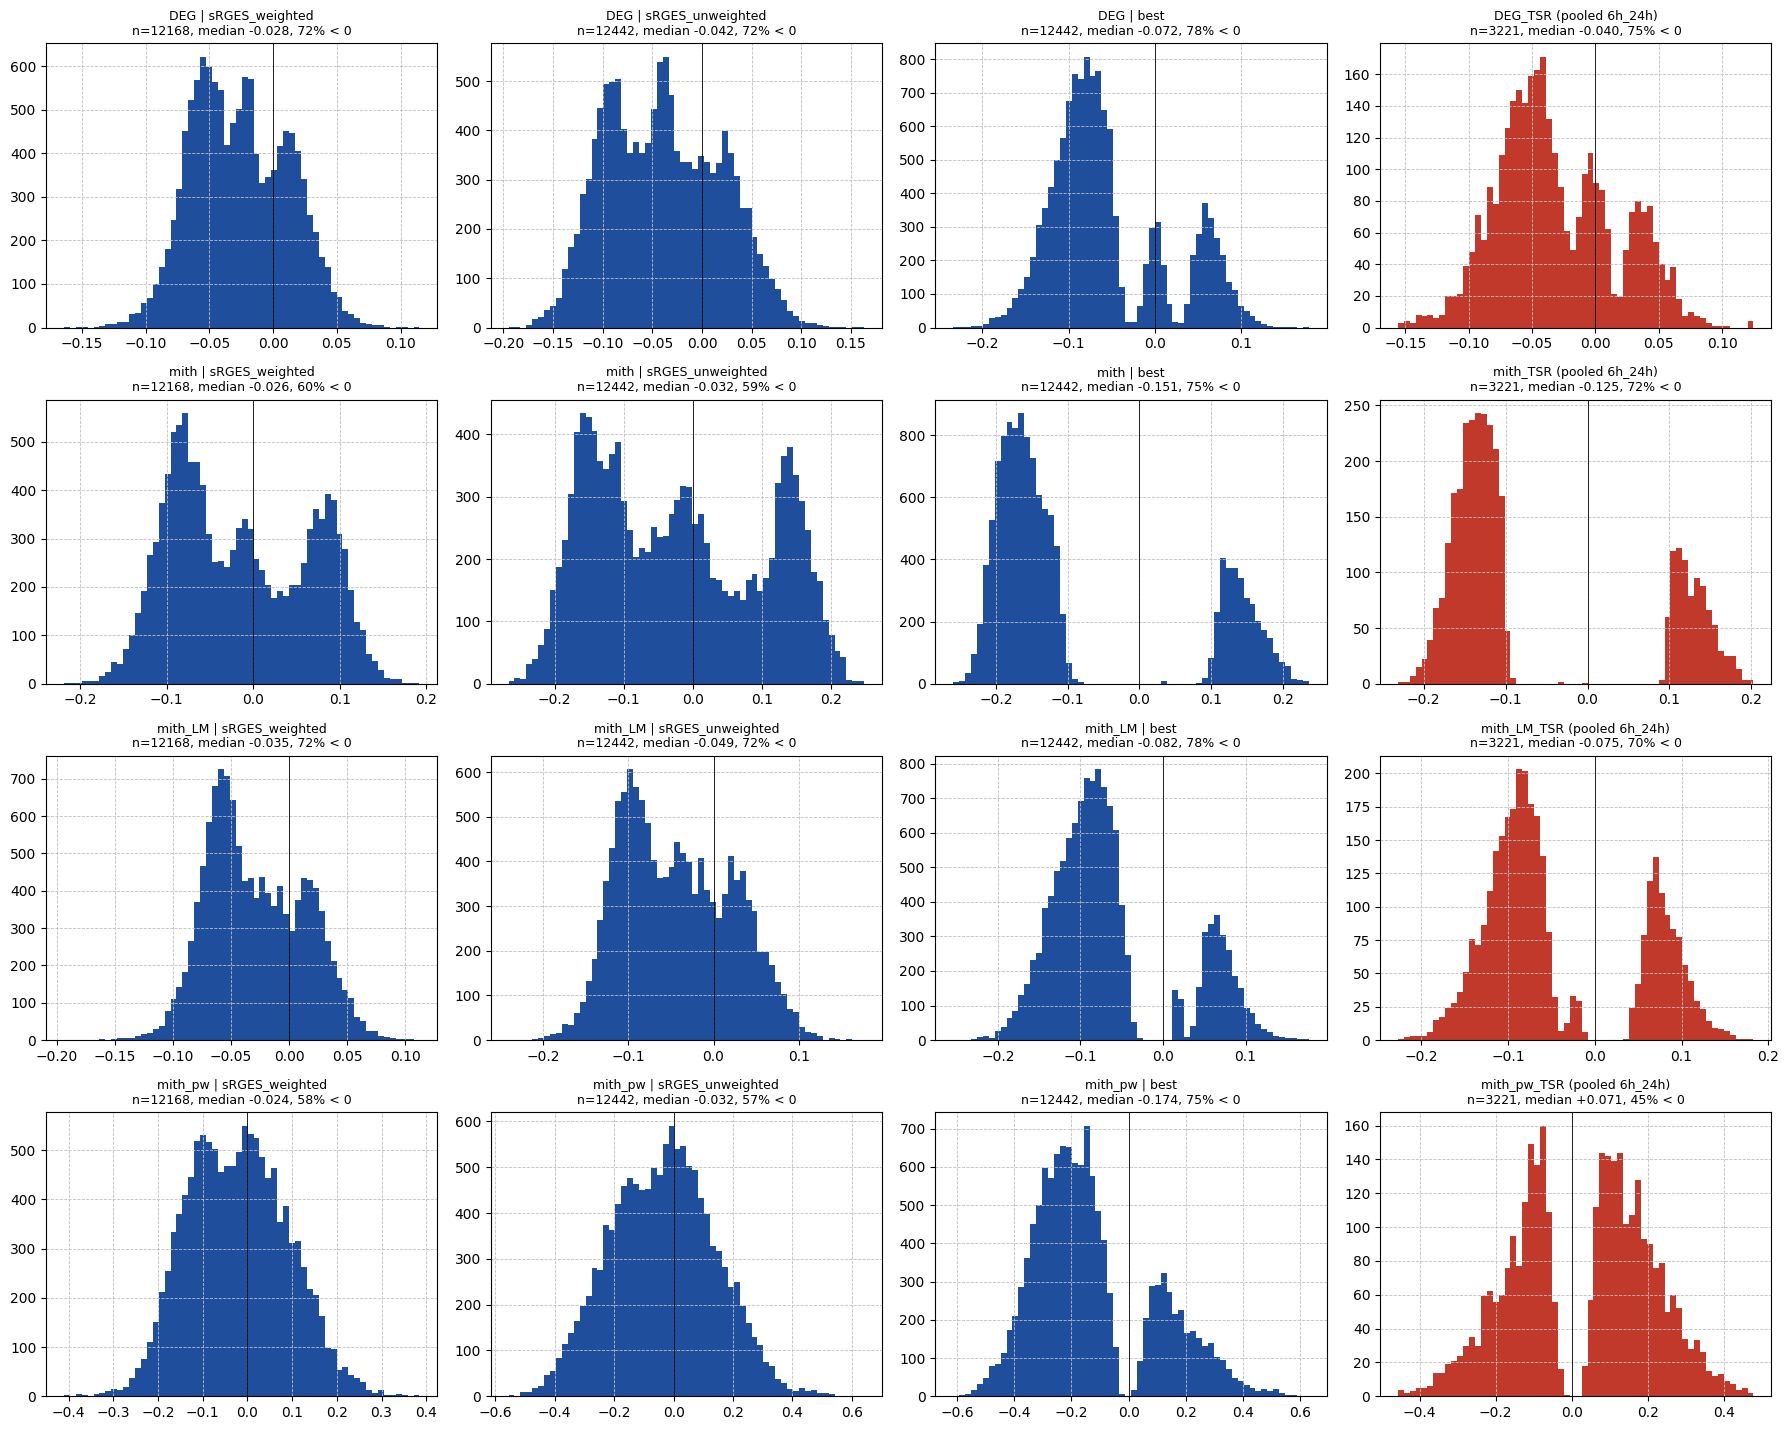

In [6]:
fig, axes = plt.subplots(len(CONFIGS), 4, figsize=(18, 3.6 * len(CONFIGS)), squeeze=False)
for i, c in enumerate(CONFIGS):
    for j, coll in enumerate(COLLAPSES):
        v = s[(s.config == c) & (s.collapse == coll)]['score']
        a = axes[i, j]; a.hist(v, bins=60, color=BLUE)
        a.axvline(0, color='k', lw=.6)
        a.set_title(f'{c} | {coll}\nn={len(v)}, median {v.median():+.3f}, {100 * (v < 0).mean():.0f}% < 0', fontsize=9)
    v = tsr[c]; a = axes[i, 3]; a.hist(v, bins=60, color=RED); a.axvline(0, color='k', lw=.6)
    a.set_title(f'{c}_TSR (pooled 6h_24h)\nn={len(v)}, median {v.median():+.3f}, {100 * (v < 0).mean():.0f}% < 0', fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_score_distributions.png'), dpi=120); plt.show()

## 4. Agreement between collapses and with the TSR pipeline

Spearman correlation of per-compound scores, on the compounds present in both (sRGES compounds
matched to TSR by L1000 name; several compounds with the same name are averaged).

,config,x,y,n,spearman
0,DEG,sRGES_weighted,sRGES_unweighted,12166,0.963
1,DEG,sRGES_weighted,best,12166,0.602
2,DEG,sRGES_weighted,DEG_TSR,3053,0.524
3,DEG,sRGES_unweighted,best,12440,0.580
4,DEG,sRGES_unweighted,DEG_TSR,3076,0.542
5,DEG,best,DEG_TSR,3076,0.521
6,mith,sRGES_weighted,sRGES_unweighted,12166,0.964
7,mith,sRGES_weighted,best,12166,0.670
8,mith,sRGES_weighted,mith_TSR,3053,0.393
9,mith,sRGES_unweighted,best,12440,0.665


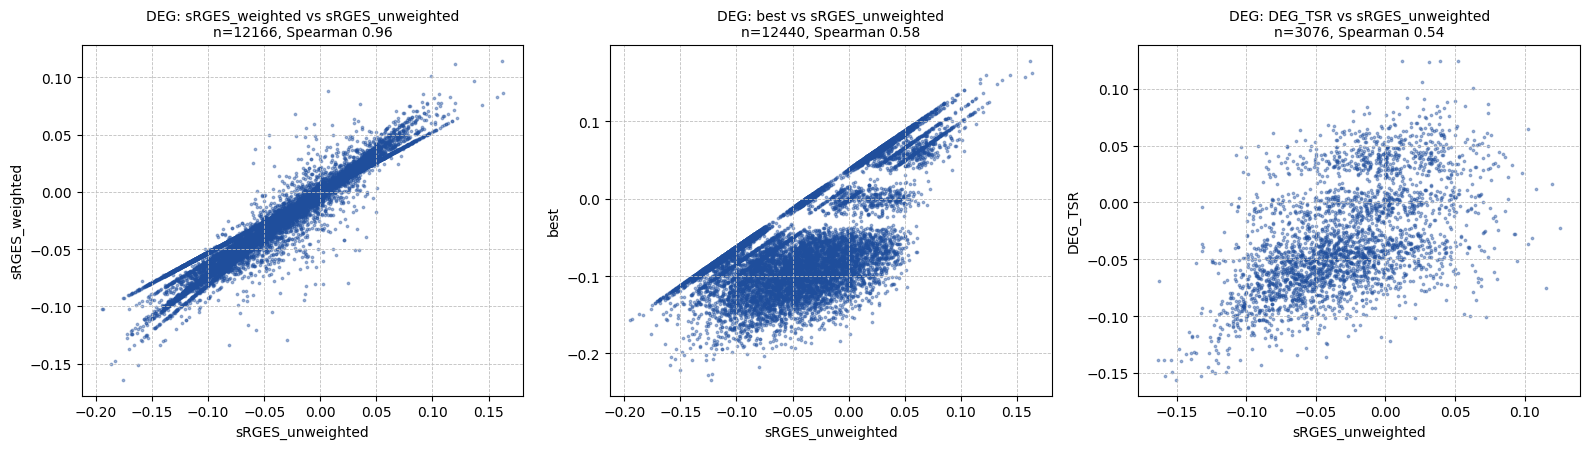

In [7]:
rows = []
for c in CONFIGS:
    piv = s[s.config == c].groupby(['k', 'collapse'])['score'].mean().unstack()
    piv[f'{c}_TSR'] = tsr[c].reindex(piv.index)
    cols = COLLAPSES + [f'{c}_TSR']
    for a_ in range(len(cols)):
        for b_ in range(a_ + 1, len(cols)):
            d = piv[[cols[a_], cols[b_]]].dropna()
            rows.append({'config': c, 'x': cols[a_], 'y': cols[b_], 'n': len(d),
                         'spearman': stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1]).statistic})
agree = pd.DataFrame(rows); display(agree.round(3))

c = CONFIGS[0]
piv = s[s.config == c].groupby(['k', 'collapse'])['score'].mean().unstack(); piv[f'{c}_TSR'] = tsr[c].reindex(piv.index)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (x, y) in zip(ax, [('sRGES_unweighted', 'sRGES_weighted'), ('sRGES_unweighted', 'best'), ('sRGES_unweighted', f'{c}_TSR')]):
    d = piv[[x, y]].dropna()
    a.scatter(d[x], d[y], s=3, alpha=.4, color=BLUE)
    a.set_xlabel(x); a.set_ylabel(y)
    a.set_title(f'{c}: {y} vs {x}\nn={len(d)}, Spearman {stats.spearmanr(d[x], d[y]).statistic:.2f}', fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, f'{DISEASE}_srges_agreement.png'), dpi=120); plt.show()

### 4.1 Consensus of the sRGES and wsRGES rankings

For every per-instance configuration (`DEG`, `mith`, `mith_LM`, `mith_pw`) × (`sRGES`, `wsRGES`), the
compounds scored by all eight rankings are re-ranked within each ranking (percentile, low = stronger
reversal) and the eight percentiles are averaged (`mean_pct`). A low `mean_pct` means a compound reverses
the signature in every configuration. `sRGES` and `wsRGES` of the same configuration correlate at about
0.97, so each configuration enters twice with nearly the same information.

In [8]:
C10 = [f'{c}_{v}' for c in ['DEG', 'mith', 'mith_LM', 'mith_pw'] for v in ('sRGES', 'wsRGES') if f'{c}_{v}' in W]
P10 = consensus(W, C10)
print(f'{len(C10)} rankings; {len(P10)} compounds scored by all of them (percentiles recomputed on these)')
t = P10.head(25).round(1); t.insert(0, 'drug', t.index.map(NAME)); display(t)
print('known drugs in this consensus:')
display(P10.reindex(KNOWN)[['mean_pct', 'consensus_rank']].round(1).assign(of=len(P10)))

8 rankings; 12166 compounds scored by all of them (percentiles recomputed on these)


,drug,DEG_sRGES,DEG_wsRGES,mith_sRGES,mith_wsRGES,mith_LM_sRGES,mith_LM_wsRGES,mith_pw_sRGES,mith_pw_wsRGES,mean_pct,consensus_rank
k,,,,,,,,,,,
brdk77144489,BRD-K77144489,1.6,0.4,5.5,1.3,0.6,0.1,2.0,0.3,1.5,1
brdk38126560,BRD-K38126560,2.2,1.2,5.5,2.5,1.9,0.8,0.6,0.2,1.9,2
brdk07686903,BRD-K07686903,0.4,4.1,0.3,5.0,0.3,2.6,1.0,2.5,2.0,3
brdk71894218,BRD-K71894218,3.8,0.9,2.2,0.5,6.2,1.3,2.2,0.3,2.2,4
brdk88488723,BRD-K88488723,1.7,1.2,2.4,1.6,5.2,2.8,2.7,0.7,2.3,5
brdk29582182,BRD-K29582182,1.9,0.5,7.9,1.9,3.0,0.6,2.3,0.3,2.3,6
brdk14131832,BRD-K14131832,1.9,9.0,0.1,2.9,0.2,2.3,0.5,1.7,2.3,7
sa243193,SA-243193,0.7,2.4,1.5,4.5,0.6,1.6,4.2,3.9,2.4,8
sa1459854,SA-1459854,0.6,1.8,3.7,5.0,0.8,1.8,3.4,2.4,2.4,9


known drugs in this consensus:


,mean_pct,consensus_rank,of
k,,,
pirfenidone,NaN,NaN,12166
nintedanib,37.7,3886.0,12166


## 5. Top-ranked compounds

In [9]:
TOP = 20
for c in CONFIGS:
    tabs = {}
    for coll in COLLAPSES:
        d = s[(s.config == c) & (s.collapse == coll)].sort_values('score').head(TOP)
        tabs[coll] = [f'{n} ({v:+.3f}, {int(k)} inst)' for n, v, k in zip(d.pert_iname, d.score, d.n_instances)]
    t = tsr[c].sort_values().head(TOP)
    tabs[f'{c}_TSR (pooled 6h_24h)'] = [f'{n} ({v:+.3f})' for n, v in t.items()]
    print(f'=== {c} ==='); display(pd.DataFrame(tabs, index=range(1, TOP + 1)))

MIN_INST = 3
for c in CONFIGS:
    tabs = {}
    for coll in COLLAPSES:
        d = s[(s.config == c) & (s.collapse == coll) & (s.n_instances >= MIN_INST)].sort_values('score').head(TOP)
        tabs[coll] = [f'{n} ({v:+.3f}, {int(k)} inst, {int(l)} lines)' for n, v, k, l in zip(d.pert_iname, d.score, d.n_instances, d.n_cell_lines)]
    print(f'=== {c}, compounds with >= {MIN_INST} instances ==='); display(pd.DataFrame(tabs, index=range(1, TOP + 1)))
u = s[(s.config == CONFIGS[0]) & (s.collapse == 'sRGES_unweighted')]
for k, g in u.groupby(pd.cut(u.n_instances, [0, 1, 2, 5, 20, 10**6], labels=['1', '2', '3-5', '6-20', '>20']), observed=False):
    print(f'instances {k:>5s}: n={len(g):5d}  score sd {g.score.std():.3f}  share in top 1% {100 * (g.score <= u.score.quantile(.01)).mean():.1f}%')

=== DEG ===


,sRGES_weighted,sRGES_unweighted,best,DEG_TSR (pooled 6h_24h)
1,"kepone (-0.164, 2 inst)","BRD-K46653995 (-0.195, 1 inst)","wortmannin (-0.234, 582 inst)",homoharringtonine (-0.156)
2,"tributyltin (-0.152, 2 inst)","BRD-K43852369 (-0.193, 1 inst)","emetine (-0.228, 115 inst)",cephaeline (-0.153)
3,"BRD-K70923866 (-0.150, 1 inst)","BRD-K70923866 (-0.187, 1 inst)","narciclasine (-0.227, 74 inst)",qlx138 (-0.153)
4,"BRD-K56647759 (-0.148, 1 inst)","BRD-K56647759 (-0.183, 1 inst)","homoharringtonine (-0.221, 65 inst)",jw7241 (-0.150)
5,"BRD-K78130859 (-0.137, 1 inst)","BRD-K07660364 (-0.176, 1 inst)","tozasertib (-0.217, 138 inst)",verrucarina (-0.150)
6,"thonzonium (-0.134, 1 inst)","kepone (-0.176, 2 inst)","PI-828 (-0.215, 18 inst)",qlxii47 (-0.149)
7,"BRD-K16346331 (-0.133, 1 inst)","BRD-K27638907 (-0.175, 1 inst)","neratinib (-0.208, 73 inst)",emetine (-0.149)
8,"zearalenone (-0.133, 3 inst)","BRD-K68735643 (-0.172, 1 inst)","PI-103 (-0.208, 87 inst)",tyrphostinag126 (-0.145)
9,"cephaeline (-0.131, 13 inst)","BRD-K01777999 (-0.172, 1 inst)","torin-2 (-0.207, 61 inst)",wz4145 (-0.145)
10,"methoxychlor (-0.131, 1 inst)","BRD-K94534355 (-0.172, 2 inst)","MK-2206 (-0.207, 69 inst)",gsk1070916 (-0.143)


=== mith ===


,sRGES_weighted,sRGES_unweighted,best,mith_TSR (pooled 6h_24h)
1,"W-12 (-0.219, 1 inst)","BRD-K77987559 (-0.267, 1 inst)","estradiol (-0.260, 75 inst)",st4029573 (-0.232)
2,"BRD-K11778076 (-0.211, 1 inst)","BRD-K49595590 (-0.263, 1 inst)","biochanin-a (-0.258, 4 inst)",homoharringtonine (-0.226)
3,"BRD-K22458275 (-0.209, 1 inst)","BRD-K02861439 (-0.260, 1 inst)","BRD-K42678365 (-0.254, 2 inst)",bufalin (-0.222)
4,"BRD-K47490989 (-0.200, 1 inst)","BRD-K22458275 (-0.259, 1 inst)","BRD-K41513229 (-0.253, 3 inst)",ran29 (-0.220)
5,"BRD-K45763312 (-0.199, 1 inst)","BRD-K78235165 (-0.258, 1 inst)","doxylamine (-0.252, 5 inst)",qlxii47 (-0.217)
6,"prednisone (-0.197, 1 inst)","BRD-K84787606 (-0.258, 1 inst)","coumestrol (-0.251, 6 inst)",psb069 (-0.215)
7,"KU-C103676 (-0.194, 1 inst)","BRD-K11901011 (-0.257, 1 inst)","PJ-34 (-0.247, 36 inst)",tyrphostinag126 (-0.214)
8,"BRD-K28162668 (-0.194, 1 inst)","BRD-K14131832 (-0.256, 1 inst)","BMS-536924 (-0.245, 71 inst)",proscillaridin (-0.212)
9,"icosapent (-0.193, 1 inst)","BRD-K83860226 (-0.253, 1 inst)","BRD-K83577967 (-0.245, 1 inst)",digoxin (-0.212)
10,"PATI-1-2-3 (-0.193, 2 inst)","BRD-K38370145 (-0.253, 1 inst)","narciclasine (-0.245, 74 inst)",narciclasine (-0.211)


=== mith_LM ===


,sRGES_weighted,sRGES_unweighted,best,mith_LM_TSR (pooled 6h_24h)
1,"BRD-K83507699 (-0.194, 1 inst)","BRD-K83507699 (-0.241, 1 inst)","razoxane (-0.254, 10 inst)",cg930 (-0.227)
2,"BRD-K15888437 (-0.161, 1 inst)","BRD-K07833219 (-0.220, 1 inst)","homoharringtonine (-0.243, 65 inst)",brda57107094 (-0.214)
3,"kepone (-0.160, 2 inst)","BRD-K46653995 (-0.219, 1 inst)","azelastine (-0.238, 2 inst)",ici199441 (-0.214)
4,"BRD-K56647759 (-0.159, 1 inst)","BRD-K07660364 (-0.208, 1 inst)","MK-2206 (-0.230, 69 inst)",brdk07877311 (-0.213)
5,"idazoxan (-0.159, 1 inst)","BRD-K94534355 (-0.206, 2 inst)","PP-2 (-0.229, 18 inst)",gdc0879 (-0.212)
6,"BRD-K28162668 (-0.156, 1 inst)","BRD-K61082257 (-0.205, 1 inst)","enalaprilat (-0.225, 2 inst)",tribenoside (-0.211)
7,"BRD-K70923866 (-0.153, 1 inst)","BRD-K08570368 (-0.204, 1 inst)","emetine (-0.224, 115 inst)",verrucarina (-0.204)
8,"paromomycin (-0.152, 1 inst)","BRD-K46319090 (-0.202, 1 inst)","calyculin (-0.223, 15 inst)",wz4145 (-0.201)
9,"BRD-K55191691 (-0.147, 1 inst)","BRD-K49749421 (-0.202, 1 inst)","CG-930 (-0.221, 24 inst)",l694247 (-0.201)
10,"tributyltin (-0.145, 2 inst)","BRD-K56647759 (-0.197, 1 inst)","trichostatin-a (-0.221, 803 inst)",mln8054 (-0.197)


... (7 outputs left out)

,sRGES_weighted,sRGES_unweighted,best
1,"actinomycin-d (-0.138, 3 inst, 1 lines)","BRD-K06973013 (-0.193, 3 inst, 2 lines)","razoxane (-0.254, 10 inst, 8 lines)"
2,"cephaeline (-0.134, 13 inst, 8 lines)","BRD-K04076294 (-0.188, 3 inst, 2 lines)","homoharringtonine (-0.243, 65 inst, 13 lines)"
3,"verrucarin-a (-0.130, 10 inst, 8 lines)","SA-1459854 (-0.168, 4 inst, 2 lines)","MK-2206 (-0.230, 69 inst, 41 lines)"
4,"BRD-K34332553 (-0.124, 4 inst, 3 lines)","BRD-K01448700 (-0.168, 3 inst, 2 lines)","PP-2 (-0.229, 18 inst, 12 lines)"
5,"cadmium-chloride (-0.123, 3 inst, 1 lines)","BRD-K96194602 (-0.163, 3 inst, 2 lines)","emetine (-0.224, 115 inst, 49 lines)"
6,"BRD-K06973013 (-0.122, 3 inst, 2 lines)","homoharringtonine (-0.163, 65 inst, 13 lines)","calyculin (-0.223, 15 inst, 8 lines)"
7,"JTC-801 (-0.121, 4 inst, 3 lines)","peruvoside (-0.161, 3 inst, 1 lines)","CG-930 (-0.221, 24 inst, 13 lines)"
8,"torin-2 (-0.120, 50 inst, 13 lines)","cephaeline (-0.161, 17 inst, 12 lines)","trichostatin-a (-0.221, 803 inst, 57 lines)"
9,"zearalenone (-0.119, 3 inst, 1 lines)","SA-1459172 (-0.158, 3 inst, 2 lines)","KIN001-242 (-0.220, 36 inst, 12 lines)"
10,"homoharringtonine (-0.118, 58 inst, 10 lines)","BRD-K53407305 (-0.157, 3 inst, 2 lines)","wortmannin (-0.220, 582 inst, 50 lines)"


=== mith_pw, compounds with >= 3 instances ===


,sRGES_weighted,sRGES_unweighted,best
1,"SC-10 (-0.269, 3 inst, 3 lines)","SA-1459172 (-0.371, 3 inst, 2 lines)","PSB-11 (-0.614, 5 inst, 4 lines)"
2,"BRD-K45542213 (-0.256, 3 inst, 3 lines)","SA-1459854 (-0.349, 4 inst, 2 lines)","BRD-K80400482 (-0.613, 5 inst, 4 lines)"
3,"BRD-K22630935 (-0.255, 3 inst, 3 lines)","BRD-K26626929 (-0.342, 4 inst, 3 lines)","wortmannin (-0.592, 582 inst, 50 lines)"
4,"BRD-A02747686 (-0.249, 3 inst, 3 lines)","BRD-K20490522 (-0.341, 3 inst, 3 lines)","BRD-K22546959 (-0.580, 8 inst, 6 lines)"
5,"BRD-K81408913 (-0.247, 4 inst, 3 lines)","BRD-K44421914 (-0.340, 3 inst, 2 lines)","BRD-K31030218 (-0.575, 6 inst, 3 lines)"
6,"SJB-shh-31 (-0.245, 4 inst, 3 lines)","BRD-K45542213 (-0.335, 3 inst, 3 lines)","GW-9662 (-0.573, 8 inst, 6 lines)"
7,"BRD-K17773477 (-0.238, 3 inst, 3 lines)","n-formylmethionylalanine (-0.332, 3 inst, 3 li...","estradiol-benzoate (-0.570, 9 inst, 7 lines)"
8,"BRD-K01981286 (-0.233, 3 inst, 2 lines)","BRD-K70595525 (-0.331, 3 inst, 1 lines)","TUL_XIX002 (-0.565, 12 inst, 2 lines)"
9,"BRD-K44421914 (-0.231, 3 inst, 2 lines)","BRD-K95033227 (-0.331, 6 inst, 6 lines)","allantoin (-0.564, 8 inst, 4 lines)"
10,"BRD-K20490522 (-0.231, 3 inst, 3 lines)","BRD-K42677417 (-0.326, 3 inst, 2 lines)","alprenolol (-0.557, 5 inst, 5 lines)"


instances     1: n= 5041  score sd 0.069  share in top 1% 2.0%
instances     2: n= 2090  score sd 0.056  share in top 1% 0.5%
instances   3-5: n= 2472  score sd 0.047  share in top 1% 0.2%
instances  6-20: n= 2307  score sd 0.039  share in top 1% 0.1%
instances   >20: n=  532  score sd 0.041  share in top 1% 0.8%


## 6. Effect of the CCLE cell-line weight

Weighted sRGES multiplies every instance by `cor / max(cor)` (cor = median correlation of the line
with the IPF lung samples) and leaves out the 13 lines without CCLE expression.

In [10]:
for c in CONFIGS:
    w = s[(s.config == c) & (s.collapse == 'sRGES_weighted')].set_index('pert_iname')['score']
    u = s[(s.config == c) & (s.collapse == 'sRGES_unweighted')].set_index('pert_iname')['score']
    d = pd.concat([u.rename('unweighted'), w.rename('weighted')], axis=1).dropna()
    ru, rw = d['unweighted'].rank(pct=True), d['weighted'].rank(pct=True)
    print(f'{c}: n={len(d)}, Spearman {stats.spearmanr(d.unweighted, d.weighted).statistic:.3f}; '
          f'median |percentile shift| {100 * (ru - rw).abs().median():.1f} points; '
          f'top-100 overlap {len(set(d.unweighted.nsmallest(100).index) & set(d.weighted.nsmallest(100).index))}/100')
display(weights.sort_values('cor', ascending=False).head(10).round(3))

DEG: n=12168, Spearman 0.963; median |percentile shift| 3.6 points; top-100 overlap 40/100


mith: n=12168, Spearman 0.964; median |percentile shift| 4.8 points; top-100 overlap 17/100
mith_LM: n=12168, Spearman 0.956; median |percentile shift| 3.7 points; top-100 overlap 31/100


mith_pw: n=12168, Spearman 0.978; median |percentile shift| 3.3 points; top-100 overlap 38/100


,lincs_cell_id,cor
0,NCIH596,0.537
3,HA1E,0.501
1,MDAMB231,0.491
4,OV7,0.485
2,COV644,0.474
5,T3M10,0.465
7,HS578T,0.457
6,HUH7,0.446
9,NCIH2073,0.443
8,HCC515,0.439


## 7. Known IPF drugs

From `ipf_known_drug_ranks.tsv` (the pipeline's `known_drugs` validation). Percentile = rank(pct) × 100 in
ascending score (low = stronger reversal): `percentile` among all the compounds the ranking scores (own universe),
`percentile_shared_DEG` among the TSR ∩ per-instance compounds (section 2.1), `percentile_stratum` among the
compounds with a similar number of instances (stratum). NaN = not scored.

In [11]:
R = [f'{c}_TSR' for c in TSR_CONFIGS] + [f'{c}_{v}' for c in CONFIGS for v in ('sRGES', 'wsRGES', 'best')]
for v in ['percentile', 'percentile_shared_DEG', 'percentile_stratum', 'score']:
    print(v)
    display(kn[kn.ranking.isin(R)].pivot_table(index='drug_key', columns='ranking', values=v).reindex(index=KNOWN, columns=R).round(3))
print('instances behind each known drug (per-instance route):')
display(kn[kn.ranking.isin([f'{c}_sRGES' for c in CONFIGS])].pivot_table(index='drug_key', columns='ranking',
        values=['n_instances', 'n_cell_lines']).reindex(KNOWN))

percentile


ranking,DEG_TSR,DEG_LM_TSR,mith_TSR,mith_LM_TSR,mith_pw_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,mith_sRGES,mith_wsRGES,mith_best,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best
drug_key,,,,,,,,,,,,,,,,,
pirfenidone,89.382,60.571,75.101,92.487,8.072,44.011,NaN,65.993,57.460,NaN,48.416,66.005,NaN,19.236,22.436,NaN,1.375
nintedanib,8.227,11.829,24.495,23.657,50.947,15.386,7.307,1.929,47.524,52.458,29.711,11.809,7.965,2.219,78.505,80.75,28.489


percentile_shared_DEG


ranking,DEG_TSR,DEG_LM_TSR,mith_TSR,mith_LM_TSR,mith_pw_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,mith_sRGES,mith_wsRGES,mith_best,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best
drug_key,,,,,,,,,,,,,,,,,
pirfenidone,89.467,60.566,75.000,92.393,8.062,33.388,NaN,89.012,61.053,NaN,73.635,65.377,NaN,42.295,6.664,NaN,3.836
nintedanib,8.420,12.094,24.577,23.667,50.683,5.104,5.077,5.624,44.766,55.847,52.568,3.804,6.649,6.567,84.980,83.262,53.381


percentile_stratum


ranking,DEG_TSR,DEG_LM_TSR,mith_TSR,mith_LM_TSR,mith_pw_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,mith_sRGES,mith_wsRGES,mith_best,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best
drug_key,,,,,,,,,,,,,,,,,
pirfenidone,NaN,NaN,NaN,NaN,NaN,42.508,NaN,64.385,57.683,NaN,43.705,69.363,NaN,8.712,24.174,NaN,0.191
nintedanib,NaN,NaN,NaN,NaN,NaN,7.905,7.719,7.213,53.261,64.561,65.613,4.348,9.24,8.498,94.466,95.205,67.589


score


ranking,DEG_TSR,DEG_LM_TSR,mith_TSR,mith_LM_TSR,mith_pw_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,mith_sRGES,mith_wsRGES,mith_best,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best
drug_key,,,,,,,,,,,,,,,,,
pirfenidone,0.038,-0.049,0.103,0.097,-0.226,-0.051,NaN,-0.053,-0.006,NaN,-0.153,-0.015,NaN,-0.124,-0.177,NaN,-0.475
nintedanib,-0.091,-0.109,-0.149,-0.107,0.075,-0.101,-0.076,-0.160,-0.043,-0.019,-0.176,-0.118,-0.081,-0.173,0.104,0.079,-0.261


instances behind each known drug (per-instance route):


n_cell_lines                                        n_instances                                       
ranking        DEG_sRGES mith_LM_sRGES mith_pw_sRGES mith_sRGES   DEG_sRGES mith_LM_sRGES mith_pw_sRGES mith_sRGES
drug_key                                                                                                          
pirfenidone          2.0           2.0           2.0        2.0         2.0           2.0           2.0        2.0
nintedanib           6.0           6.0           6.0        6.0        17.0          17.0          17.0       17.0

## 8. Configurations with CS runs on every cell line

The sRGES tables cover the configurations whose per-instance CS runs exist for all 71 cell lines
(`ipf_srges_cs_runs_used.tsv`); any other configuration is listed below.

In [12]:
print('configurations without CS runs on all lines:', PENDING or 'none')

configurations without CS runs on all lines: none


## 9. Notes

The numbers and the reading of these tables are in the case-study report
(`other_outputs/case_studies/ipf/report_srges_ipf.md`); this notebook shows the tables and figures behind it.
Every number above is printed by the cell that computes it.

## 10. Top-line sRGES: only the cell lines above a random-pair cutoff

sRGES and wsRGES average over every LINCS line, although most lines sit in the middle of the
similarity distribution. The top-line variants keep only the LINCS lines whose weight (median
Spearman correlation with the case samples, primary gene set `binchen2017_iqr5000`) exceeds a
cutoff taken from the correlation between two unrelated cell lines: all 40,000 pairs between two
disjoint sets of 200 random CCLE lines (seed 0). Cutoffs: `q3` = third quartile, `median`.
Collapses `sRGES_(un)weighted_top_<cutoff>` (`<config>_sRGES_topQ3` / `_wsRGES_topQ3` /
`_sRGES_topMed` / `_wsRGES_topMed` in the rankings); dose/time offsets as in sRGES; a compound is
scored only if it was profiled on at least one top line. `DEG_LM` = `DEG` in this route (landmark-only
drug signatures).

,comparison,n_pairs,q1,median,q3
0,random CCLE pairs (200 x 200),40000,0.385,0.451,0.554
1,LINCS line pairs,1653,0.446,0.514,0.600


cutoff q3 = 0.554: 0 lines 
cutoff median = 0.451: 7 lines NCIH596 (0.537), HA1E (0.501), MDAMB231 (0.491), OV7 (0.485), COV644 (0.474), T3M10 (0.465), HS578T (0.457)


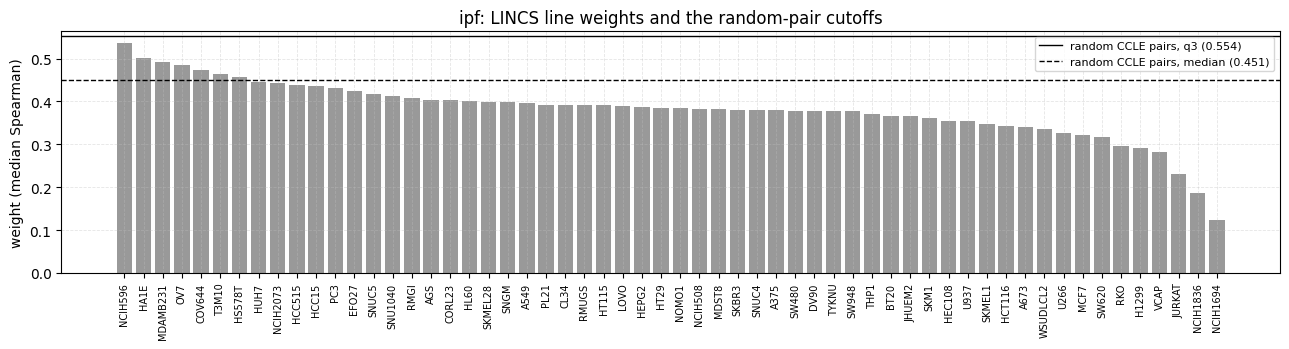

In [13]:
OO = os.path.join(NETCOS_ROOT, 'other_outputs', 'case_studies', DISEASE)
ref = pd.read_csv(os.path.join(OO, f'{DISEASE}_ccle_reference_scale.tsv'), sep='\t')
top = pd.read_csv(os.path.join(OO, f'{DISEASE}_top_cell_lines.tsv'), sep='\t')
wts = pd.read_csv(os.path.join(OO, f'{DISEASE}_cell_line_weights.tsv'), sep='\t').sort_values('cor', ascending=False)
display(ref.round(3))
for cut, g in top.groupby('cutoff', sort=False):
    l = g.dropna(subset=['lincs_cell_id'])
    print(f'cutoff {cut} = {g.threshold.iloc[0]:.3f}: {len(l)} lines', ', '.join(f'{c} ({v:.3f})' for c, v in zip(l.lincs_cell_id, l.cor)))
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(range(len(wts)), wts.cor, color='0.6')
for q, ls_ in (('q3', '-'), ('median', '--')):
    ax.axhline(ref[q].iloc[0], color='k', ls=ls_, lw=1, label=f'random CCLE pairs, {q} ({ref[q].iloc[0]:.3f})')
ax.set_xticks(range(len(wts))); ax.set_xticklabels(wts.lincs_cell_id, rotation=90, fontsize=7)
ax.set_ylabel('weight (median Spearman)'); ax.set_title(f'{DISEASE}: LINCS line weights and the random-pair cutoffs')
ax.grid(ls='--', alpha=.4); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 10.1 Agreement with the all-line collapses and the TSR route

Spearman correlation and top-50 overlap on the compounds scored by both (low score = stronger reversal).

In [14]:
TSR = lambda cfg: tsr[cfg]   # pooled 6h_24h TSR scores of section 1
sp = pd.read_csv(os.path.join(OO, f'{DISEASE}_srges_per_drug.tsv'), sep='\t')
sp['k'] = sp['pert_iname'].astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
TOPC = [c for c in sp.collapse.unique() if '_top_' in c]
REFC = ['sRGES_unweighted', 'sRGES_weighted', 'best']
def overlap(a, b, n=50):
    return len(set(a.nsmallest(n).index) & set(b.nsmallest(n).index))

if not TOPC:
    print('no top-line rankings for this study (no LINCS line above either cutoff)')
else:
    rows = []
    for cfg, d in sp.groupby('config', sort=False):
        piv = d.groupby(['k', 'collapse'])['score'].mean().unstack()
        piv[f'{cfg}_TSR'] = TSR(cfg).reindex(piv.index)
        for t in TOPC:
            for r in REFC + [f'{cfg}_TSR']:
                x = piv[[t, r]].dropna()
                rows.append({'config': cfg, 'top_collapse': t, 'vs': r, 'n_drugs_top': int(piv[t].notna().sum()), 'n_shared': len(x),
                             'spearman': stats.spearmanr(x[t], x[r]).statistic if len(x) > 2 else np.nan,
                             'top50_overlap': overlap(x[t], x[r]) if len(x) >= 50 else np.nan})
    CMP = pd.DataFrame(rows)
    print('Spearman on shared compounds:')
    display(CMP.pivot_table(index=['config', 'top_collapse'], columns='vs', values='spearman').round(3))
    print('top-50 overlap on shared compounds (both re-ranked on the shared set):')
    display(CMP.pivot_table(index=['config', 'top_collapse'], columns='vs', values='top50_overlap'))
    print('compounds scored / shared with the TSR route:')
    display(CMP[CMP.vs.str.endswith('_TSR')][['config', 'top_collapse', 'n_drugs_top', 'n_shared']])

Spearman on shared compounds:


vs                                   DEG_TSR   best  mith_LM_TSR  mith_TSR  mith_pw_TSR  sRGES_unweighted  sRGES_weighted
config  top_collapse                                                                                                     
DEG     sRGES_unweighted_top_median    0.414  0.436          NaN       NaN          NaN             0.634           0.705
        sRGES_weighted_top_median      0.411  0.434          NaN       NaN          NaN             0.633           0.704
mith    sRGES_unweighted_top_median      NaN  0.343          NaN     0.255          NaN             0.572           0.659
        sRGES_weighted_top_median        NaN  0.342          NaN     0.253          NaN             0.571           0.658
mith_LM sRGES_unweighted_top_median      NaN  0.392        0.213       NaN          NaN             0.607           0.693
        sRGES_weighted_top_median        NaN  0.389        0.210       NaN          NaN             0.605           0.692
mith_pw sRGES_unweighted_top_median      NaN  0.338          NaN       NaN        0.165             0.524           0.608
        sRGES_weighted_top_median        NaN  0.336          NaN       NaN        0.165             0.523           0.607

top-50 overlap on shared compounds (both re-ranked on the shared set):


vs                                   DEG_TSR  best  mith_LM_TSR  mith_TSR  mith_pw_TSR  sRGES_unweighted  sRGES_weighted
config  top_collapse                                                                                                    
DEG     sRGES_unweighted_top_median     17.0  11.0          NaN       NaN          NaN              16.0            15.0
        sRGES_weighted_top_median       15.0   9.0          NaN       NaN          NaN              13.0            12.0
mith    sRGES_unweighted_top_median      NaN   3.0          NaN       2.0          NaN               9.0             5.0
        sRGES_weighted_top_median        NaN   3.0          NaN       2.0          NaN               9.0             5.0
mith_LM sRGES_unweighted_top_median      NaN   4.0          4.0       NaN          NaN               9.0             7.0
        sRGES_weighted_top_median        NaN   3.0          3.0       NaN          NaN               8.0             6.0
mith_pw sRGES_unweighted_top_median      NaN   9.0          NaN       NaN          3.0               8.0             9.0
        sRGES_weighted_top_median        NaN   9.0          NaN       NaN          3.0               8.0             9.0

compounds scored / shared with the TSR route:


,config,top_collapse,n_drugs_top,n_shared
3,DEG,sRGES_weighted_top_median,2643,1949
7,DEG,sRGES_unweighted_top_median,2643,1949
11,mith,sRGES_weighted_top_median,2643,1949
15,mith,sRGES_unweighted_top_median,2643,1949
19,mith_LM,sRGES_weighted_top_median,2643,1949
23,mith_LM,sRGES_unweighted_top_median,2643,1949
27,mith_pw,sRGES_weighted_top_median,2643,1949
31,mith_pw,sRGES_unweighted_top_median,2643,1949


### 10.2 Known IPF drugs in the top-line rankings

In [15]:
sel = [f'{c}_{v}' for c in CONFIGS for v in ('sRGES', 'wsRGES', 'sRGES_topQ3', 'wsRGES_topQ3', 'sRGES_topMed', 'wsRGES_topMed')]
sel = [r for r in sel if r in set(kn.ranking)]
display(kn[kn.ranking.isin(sel)].pivot_table(index='ranking', columns='drug_key', values=['percentile', 'score', 'n_instances']).reindex(sel).round(3))

n_instances             percentile                  score            
drug_key               nintedanib pirfenidone nintedanib pirfenidone nintedanib pirfenidone
ranking                                                                                    
DEG_sRGES                    17.0         2.0     15.386      44.011     -0.101      -0.051
DEG_wsRGES                   14.0         NaN      7.307         NaN     -0.076         NaN
DEG_sRGES_topMed              7.0         NaN     22.891         NaN     -0.095         NaN
DEG_wsRGES_topMed             7.0         NaN     27.431         NaN     -0.082         NaN
mith_sRGES                   17.0         2.0     47.524      57.460     -0.043      -0.006
mith_wsRGES                  14.0         NaN     52.458         NaN     -0.019         NaN
mith_sRGES_topMed             7.0         NaN     52.592         NaN     -0.060         NaN
mith_wsRGES_topMed            7.0         NaN     52.894         NaN     -0.053         NaN
mith_LM_sRGES                17.0         2.0     11.809      66.005     -0.118      -0.015
mith_LM_wsRGES               14.0         NaN      7.965         NaN     -0.081         NaN
mith_LM_sRGES_topMed          7.0         NaN     23.534         NaN     -0.108         NaN
mith_LM_wsRGES_topMed         7.0         NaN     27.166         NaN     -0.095         NaN
mith_pw_sRGES                17.0         2.0     78.505      22.436      0.104      -0.177
mith_pw_wsRGES               14.0         NaN     80.750         NaN      0.079         NaN
mith_pw_sRGES_topMed          7.0         NaN     68.029         NaN      0.052         NaN
mith_pw_wsRGES_topMed         7.0         NaN     67.688         NaN      0.047         NaN

### 10.3 Top compounds of the top-line rankings

In [16]:
if not TOPC:
    print('no top-line rankings for this study')
for cfg in (sp.config.unique() if TOPC else []):
    for t in TOPC:
        print(f'=== {cfg} {t}: top 10')
        display(sp[(sp.config == cfg) & (sp.collapse == t)].nsmallest(10, 'score')[['pert_iname', 'score', 'n_instances', 'n_cell_lines']].round(4))

=== DEG sRGES_weighted_top_median: top 10


,pert_iname,score,n_instances,n_cell_lines
24610,BRD-K12393722,-0.1800,1,1
24611,BRD-K10554164,-0.1766,1,1
24612,BRD-U86222656,-0.1744,1,1
24613,PI-828,-0.1703,2,1
24614,BRD-A68065211,-0.1699,1,1
24615,ispinesib,-0.1690,1,1
24616,BRD-K31688005,-0.1667,1,1
24617,BRD-A18725729,-0.1666,1,1
24618,kepone,-0.1641,2,1
24619,IKK-16,-0.1631,1,1


=== DEG sRGES_unweighted_top_median: top 10


,pert_iname,score,n_instances,n_cell_lines
27254,BRD-K12393722,-0.1930,1,1
27255,BRD-K10554164,-0.1894,1,1
27256,BRD-U86222656,-0.1870,1,1
27257,PI-828,-0.1826,2,1
27258,BRD-A68065211,-0.1822,1,1
27259,ispinesib,-0.1812,1,1
27260,BRD-K31688005,-0.1787,1,1
27261,BRD-A18725729,-0.1786,1,1
27262,kepone,-0.1759,2,1
27263,IKK-16,-0.1749,1,1


=== mith sRGES_weighted_top_median: top 10


,pert_iname,score,n_instances,n_cell_lines
66950,BRD-K46499837,-0.2418,1,1
66951,BRD-K06592610,-0.2358,1,1
66952,L-701252,-0.2324,1,1
66953,linopirdine,-0.2315,1,1
66954,BRD-K18953385,-0.2239,1,1
66955,BRD-A01973626,-0.2202,1,1
66956,aliskiren,-0.2200,1,1
66957,BRD-A19928752,-0.2199,1,1
66958,W-12,-0.2190,1,1
66959,nicotine,-0.2185,1,1


... (6 outputs left out)

=== mith_pw sRGES_weighted_top_median: top 10


,pert_iname,score,n_instances,n_cell_lines
151630,GW-9662,-0.5346,1,1
151631,alprenolol,-0.5191,1,1
151632,SC-10,-0.5082,1,1
151633,BRD-K45308677,-0.5037,1,1
151634,pinacidil,-0.4916,1,1
151635,anpirtoline,-0.4866,1,1
151636,ornidazole,-0.4734,1,1
151637,BRD-K25522720,-0.4684,1,1
151638,SJB-shh-31,-0.4604,2,1
151639,BRD-K22630935,-0.4596,1,1


=== mith_pw sRGES_unweighted_top_median: top 10


,pert_iname,score,n_instances,n_cell_lines
154274,GW-9662,-0.5732,1,1
154275,alprenolol,-0.5566,1,1
154276,SC-10,-0.5448,1,1
154277,BRD-K45308677,-0.5401,1,1
154278,pinacidil,-0.5270,1,1
154279,anpirtoline,-0.5217,1,1
154280,ornidazole,-0.5076,1,1
154281,BRD-K25522720,-0.5022,1,1
154282,SJB-shh-31,-0.4936,2,1
154283,BRD-K22630935,-0.4927,1,1


### 10.4 All rankings: TSR, per-instance all-line and per-instance top-line

Every ranking of sections 1–10 in one place: the five `_TSR` runs, the per-instance `sRGES`,
`wsRGES` and `best` of each configuration, and the top-line `sRGES` / `wsRGES` where a cutoff has lines
(where a cutoff has lines). Spearman correlation on the compounds scored by both rankings of each pair.

25 rankings; top-line rankings: ['DEG_sRGES_topMed', 'DEG_wsRGES_topMed', 'mith_sRGES_topMed', 'mith_wsRGES_topMed', 'mith_LM_sRGES_topMed', 'mith_LM_wsRGES_topMed', 'mith_pw_sRGES_topMed', 'mith_pw_wsRGES_topMed']


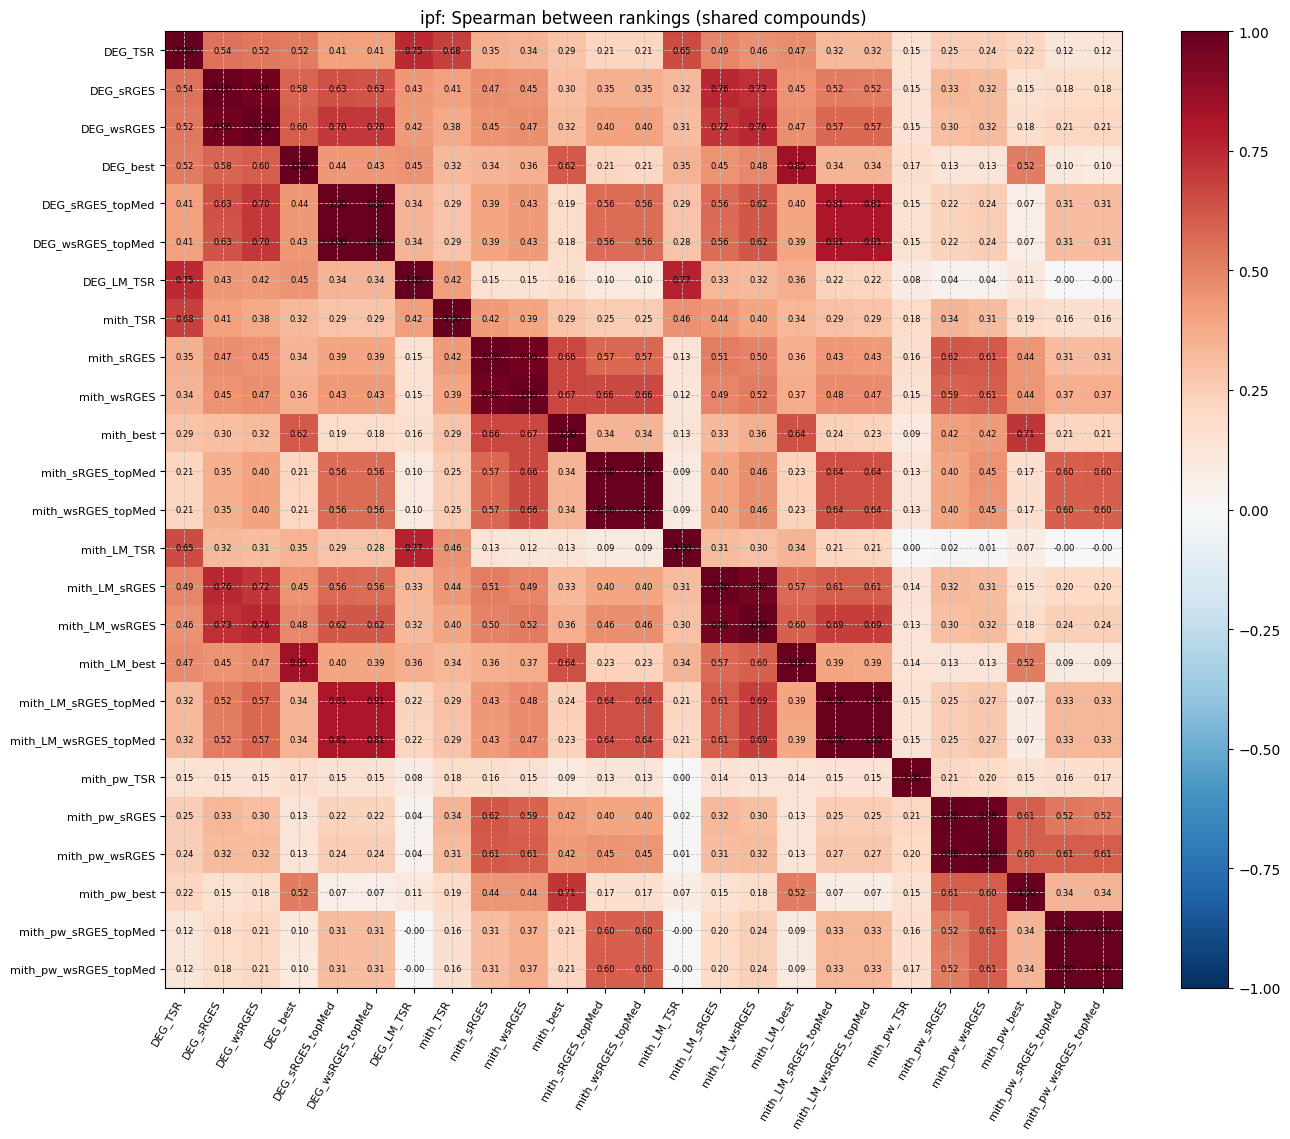

compounds shared by each top-line ranking and the other rankings:


,DEG_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,DEG_sRGES_topMed,DEG_wsRGES_topMed,DEG_LM_TSR,mith_TSR,mith_sRGES,mith_wsRGES,mith_best,mith_sRGES_topMed,mith_wsRGES_topMed,mith_LM_TSR,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_LM_sRGES_topMed,mith_LM_wsRGES_topMed,mith_pw_TSR,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best,mith_pw_sRGES_topMed,mith_pw_wsRGES_topMed
DEG_sRGES_topMed,1949,2643,2643,2643,0,2643,1949,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,2643
DEG_wsRGES_topMed,1949,2643,2643,2643,2643,0,1949,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,2643
mith_sRGES_topMed,1949,2643,2643,2643,2643,2643,1949,1949,2643,2643,2643,0,2643,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,2643
mith_wsRGES_topMed,1949,2643,2643,2643,2643,2643,1949,1949,2643,2643,2643,2643,0,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,2643
mith_LM_sRGES_topMed,1949,2643,2643,2643,2643,2643,1949,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,0,2643,1949,2643,2643,2643,2643,2643
mith_LM_wsRGES_topMed,1949,2643,2643,2643,2643,2643,1949,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,0,1949,2643,2643,2643,2643,2643
mith_pw_sRGES_topMed,1949,2643,2643,2643,2643,2643,1949,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,0,2643
mith_pw_wsRGES_topMed,1949,2643,2643,2643,2643,2643,1949,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,2643,1949,2643,2643,2643,2643,0


In [17]:
TYPES = ['TSR', 'sRGES', 'wsRGES', 'best', 'sRGES_topQ3', 'wsRGES_topQ3', 'sRGES_topMed', 'wsRGES_topMed']
ALL = [f'{c}_{t}' for c in ['DEG', 'DEG_LM', 'mith', 'mith_LM', 'mith_pw'] for t in TYPES if f'{c}_{t}' in W]
TOPLINE = [r for r in ALL if '_top' in r]
print(f'{len(ALL)} rankings; top-line rankings: {TOPLINE or "none"}')
M = pd.DataFrame(np.eye(len(ALL)), index=ALL, columns=ALL)
NS = pd.DataFrame(0, index=ALL, columns=ALL)
for i, a in enumerate(ALL):
    for b in ALL[i + 1:]:
        d = W[[a, b]].dropna()
        M.loc[a, b] = M.loc[b, a] = stats.spearmanr(d[a], d[b]).statistic if len(d) > 2 else np.nan
        NS.loc[a, b] = NS.loc[b, a] = len(d)
fig, ax = plt.subplots(figsize=(0.42 * len(ALL) + 3, 0.38 * len(ALL) + 2))
im = ax.imshow(M.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(ALL))); ax.set_xticklabels(ALL, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(ALL))); ax.set_yticklabels(ALL, fontsize=8)
for i in range(len(ALL)):
    for j in range(len(ALL)):
        ax.text(j, i, f'{M.values[i, j]:.2f}', ha='center', va='center', fontsize=6)
ax.set_title(f'{DISEASE}: Spearman between rankings (shared compounds)'); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.show()
if TOPLINE:
    print('compounds shared by each top-line ranking and the other rankings:')
    display(NS.loc[TOPLINE])

### 10.5 Known IPF drugs: TSR vs per-instance rankings, all rankings

Filled dots: percentile among all the compounds the ranking scores (its own universe). Open dots:
percentile among the TSR ∩ per-instance compounds (section 2.1; 3,053 of them for `wsRGES`, and in a top-line
ranking only the shared compounds that ranking scores — counts printed below the plot). Percentile 50 = middle
of the ranking.

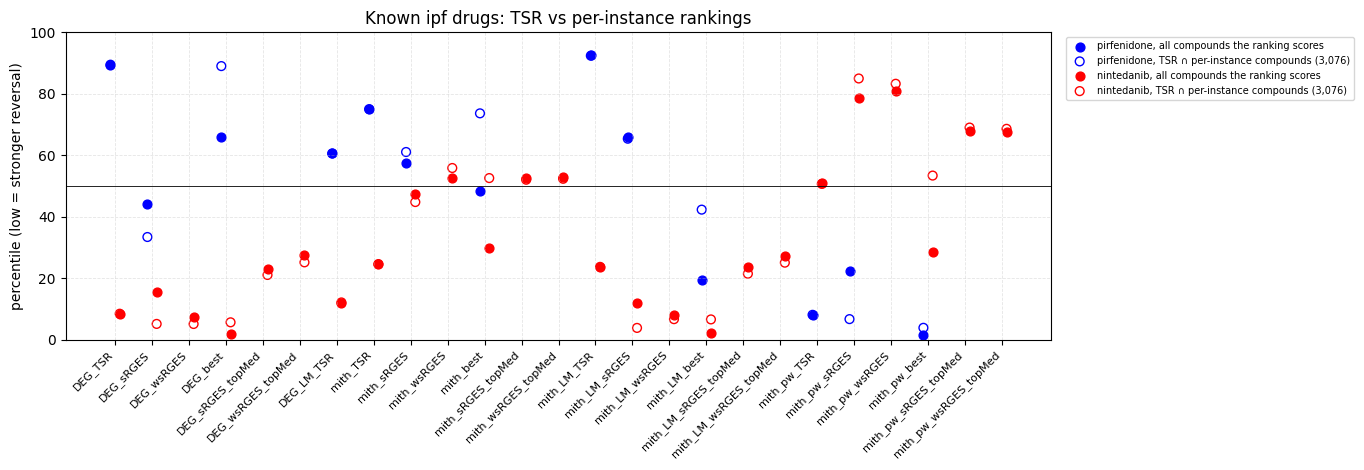

compounds in each ranking: own universe / shared set


,DEG_TSR,DEG_sRGES,DEG_wsRGES,DEG_best,DEG_sRGES_topMed,DEG_wsRGES_topMed,DEG_LM_TSR,mith_TSR,mith_sRGES,mith_wsRGES,mith_best,mith_sRGES_topMed,mith_wsRGES_topMed,mith_LM_TSR,mith_LM_sRGES,mith_LM_wsRGES,mith_LM_best,mith_LM_sRGES_topMed,mith_LM_wsRGES_topMed,mith_pw_TSR,mith_pw_sRGES,mith_pw_wsRGES,mith_pw_best,mith_pw_sRGES_topMed,mith_pw_wsRGES_topMed
own,3221,12440,12166,12440,2643,2643,3221,3221,12440,12166,12440,2643,2643,3221,12440,12166,12440,2643,2643,3221,12440,12166,12440,2643,2643
shared,3076,3076,3053,3076,1949,1949,3076,3076,3076,3053,3076,1949,1949,3076,3076,3053,3076,1949,1949,3076,3076,3053,3076,1949,1949


cross-check with the pipeline table (percentile, own universe): max |diff| 1.42e-14


In [18]:
S = set(W['DEG_TSR'].dropna().index) & set(W['DEG_sRGES'].dropna().index)
OWN = W[ALL].apply(pct)
SH = W.loc[W.index.isin(S), ALL].apply(pct)
COLOURS = ['#0000FF', '#FF0000', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b', '#e377c2']
fig, ax = plt.subplots(figsize=(max(11, 0.55 * len(ALL)), 4.8))
x = np.arange(len(ALL)); step = 0.5 / max(len(KNOWN), 1)
for i, (d, col) in enumerate(zip(KNOWN, COLOURS)):
    dx = (i - (len(KNOWN) - 1) / 2) * step
    ax.scatter(x + dx, OWN.reindex([d]).iloc[0], color=col, s=40, label=f'{d}, all compounds the ranking scores')
    ax.scatter(x + dx, SH.reindex([d]).iloc[0], facecolor='none', edgecolor=col, s=40,
               label=f'{d}, TSR ∩ per-instance compounds ({len(S):,})')
ax.axhline(50, color='k', lw=.6)
ax.set_xticks(x); ax.set_xticklabels(ALL, rotation=45, ha='right', fontsize=8); ax.set_ylim(0, 100)
ax.set_ylabel('percentile (low = stronger reversal)'); ax.grid(ls='--', alpha=.4)
ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title(f'Known {DISEASE} drugs: TSR vs per-instance rankings')
plt.tight_layout(); plt.show()
print('compounds in each ranking: own universe / shared set')
display(pd.DataFrame({'own': W[ALL].notna().sum(), 'shared': W.loc[W.index.isin(S), ALL].notna().sum()}).T)
chk = kn[kn.ranking.isin(ALL)].set_index(['drug_key', 'ranking'])['percentile']
mine = OWN.reindex(KNOWN).stack().rename('pct').reindex(chk.index)
print(f'cross-check with the pipeline table (percentile, own universe): max |diff| {(mine - chk).abs().max():.3g}')

### 10.6 Consensus of all rankings

All the rankings of the matrix above (TSR, per-instance all-line, per-instance top-line where present),
percentiles recomputed on the compounds scored by every one of them and averaged (`mean_pct`); per-family
means for the TSR, all-line and top-line rankings. The common set is limited by the smallest universe
(the top-line universe when there is one, otherwise wsRGES ∩ TSR).

In [19]:
P11 = consensus(W, ALL)
fam = {'mean_TSR': [r for r in ALL if r.endswith('_TSR')],
       'mean_all_line': [r for r in ALL if not r.endswith('_TSR') and '_top' not in r],
       'mean_top_line': TOPLINE}
for k, cols in fam.items():
    if cols:
        P11[k] = P11[cols].mean(axis=1)
print(f'{len(ALL)} rankings; {len(P11)} compounds scored by all of them (percentiles recomputed on these)')
t = P11[['mean_pct', 'consensus_rank'] + [k for k in fam if k in P11]].head(25).round(1)
t.insert(0, 'drug', t.index.map(NAME)); display(t)
print('known drugs in this consensus (NaN = not scored by every ranking):')
display(P11.reindex(KNOWN)[['mean_pct', 'consensus_rank'] + [k for k in fam if k in P11]].round(1).assign(of=len(P11)))

25 rankings; 1949 compounds scored by all of them (percentiles recomputed on these)


,drug,mean_pct,consensus_rank,mean_TSR,mean_all_line,mean_top_line
k,,,,,,
bufalin,bufalin,5.3,1,9.2,4.6,3.9
proscillaridin,proscillaridin,6.4,2,4.9,7.2,6.1
digoxin,digoxin,6.7,3,8.9,7.4,4.2
ouabain,ouabain,6.9,4,11.7,6.3,4.8
strophanthidin,strophanthidin,7.1,5,6.0,8.1,6.3
narciclasine,narciclasine,7.1,6,3.2,6.4,10.6
homoharringtonine,homoharringtonine,7.4,7,0.6,7.3,11.9
digitoxin,digitoxin,7.7,8,15.2,6.9,4.2
digitoxigenin,digitoxigenin,7.8,9,14.2,5.4,7.2


known drugs in this consensus (NaN = not scored by every ranking):


,mean_pct,consensus_rank,mean_TSR,mean_all_line,mean_top_line,of
k,,,,,,
pirfenidone,NaN,NaN,NaN,NaN,NaN,1949
nintedanib,36.6,523.0,25.9,37.5,41.8,1949
